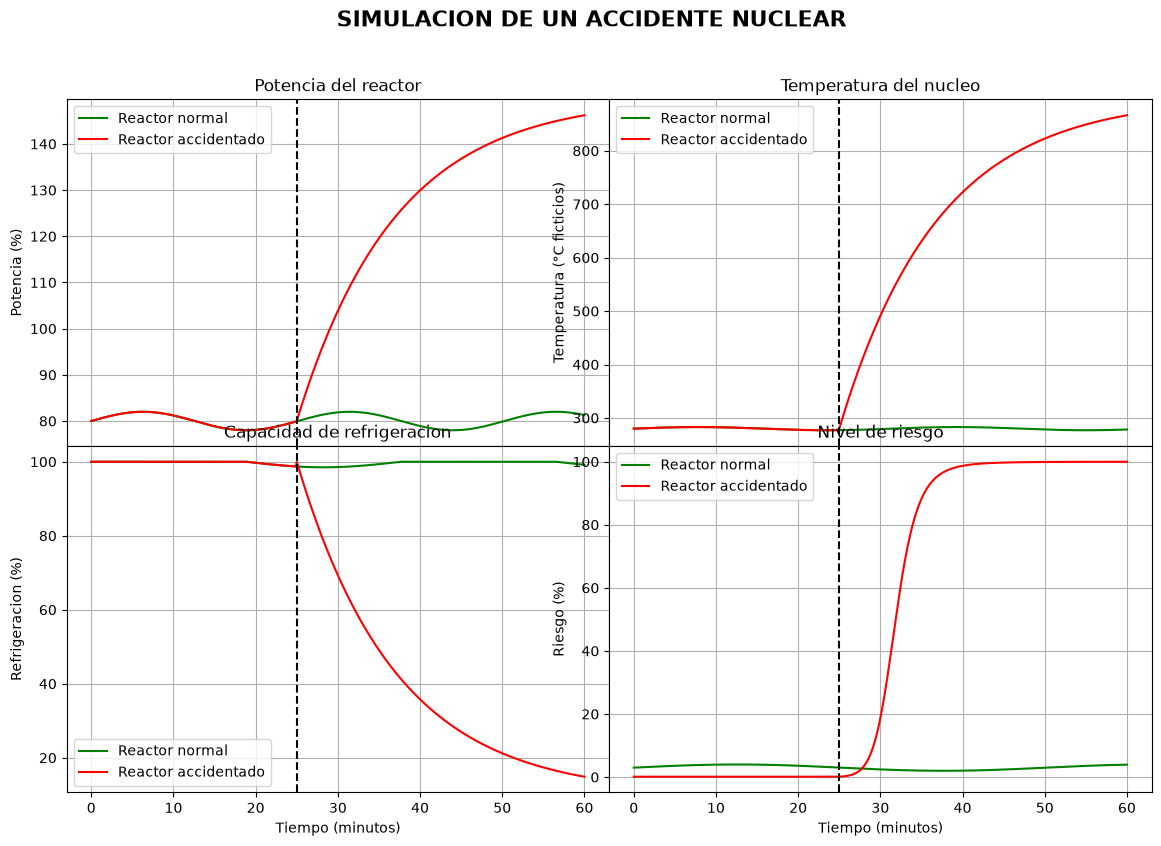

In [2]:
# Importamos las librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Eje temporal
tiempo = np.linspace(0, 60, 601) ## 601 puntos de 0 a 60 minutos
momento_accidente = 25

# Potencias
potencia_normal = 80 + 2 * np.sin(tiempo / 4)

potencia_accidente = np.where(
    tiempo < momento_accidente,
    potencia_normal,
    80 + 70 * (1 - np.exp(-(tiempo - momento_accidente) / 12))
)

# Temperaturas
temperatura_normal = 280 + 3 * np.sin(tiempo / 5)
temperatura_accidente = np.where(tiempo < momento_accidente, temperatura_normal, 280 + 620 * (1 - np.exp(-(tiempo - momento_accidente) / 12)))

# Refrigeración
refrigeracion_normal = 100 + 1.5 * np.sin(tiempo / 6)
refrigeracion_accidente = np.where(tiempo < momento_accidente, refrigeracion_normal, 10 + 90 * np.exp(-(tiempo - momento_accidente) / 12))
# Limitar los valores entre 0 y 100
refrigeracion_normal = np.clip(refrigeracion_normal, 0, 100)
refrigeracion_accidente = np.clip(refrigeracion_accidente, 0, 100)


#Riesgo
riesgo_normal = 3 + np.sin(tiempo / 8)
riesgo_accidente = 100 / (    1 + np.exp(-0.025 * (temperatura_accidente - 550)))


# =====================================================
# PASO 6: CREACION DE LAS GRAFICAS
# =====================================================

# Crear una figura con 4 graficas
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Titulo general
fig.suptitle("SIMULACION DE UN ACCIDENTE NUCLEAR",fontsize=16,fontweight="bold")


# GRAFICA 1: POTENCIA
axes[0, 0].plot(tiempo, potencia_normal,
                label="Reactor normal", color="green")

axes[0, 0].plot(tiempo, potencia_accidente,
                label="Reactor accidentado", color="red")

axes[0, 0].axvline(momento_accidente,
                   color="black", linestyle="--")

axes[0, 0].set_title("Potencia del reactor")
axes[0, 0].set_xlabel("Tiempo (minutos)")
axes[0, 0].set_ylabel("Potencia (%)")
axes[0, 0].legend()
axes[0, 0].grid(True)


# GRAFICA 2: TEMPERATURA
axes[0, 1].plot(tiempo, temperatura_normal,
                label="Reactor normal", color="green")

axes[0, 1].plot(tiempo, temperatura_accidente,
                label="Reactor accidentado", color="red")

axes[0, 1].axvline(momento_accidente,
                   color="black", linestyle="--")

axes[0, 1].set_title("Temperatura del nucleo")
axes[0, 1].set_xlabel("Tiempo (minutos)")
axes[0, 1].set_ylabel("Temperatura (°C ficticios)")
axes[0, 1].legend()
axes[0, 1].grid(True)


# GRAFICA 3: REFRIGERACION

axes[1, 0].plot(tiempo, refrigeracion_normal,
                label="Reactor normal", color="green")

axes[1, 0].plot(tiempo, refrigeracion_accidente,
                label="Reactor accidentado", color="red")

axes[1, 0].axvline(momento_accidente,
                   color="black", linestyle="--")

axes[1, 0].set_title("Capacidad de refrigeracion")
axes[1, 0].set_xlabel("Tiempo (minutos)")
axes[1, 0].set_ylabel("Refrigeracion (%)")
axes[1, 0].legend()
axes[1, 0].grid(True)


# GRAFICA 4: RIESGO

axes[1, 1].plot(tiempo, riesgo_normal,
                label="Reactor normal", color="green")

axes[1, 1].plot(tiempo, riesgo_accidente,
                label="Reactor accidentado", color="red")

axes[1, 1].axvline(momento_accidente,
                   color="black", linestyle="--")

axes[1, 1].set_title("Nivel de riesgo")
axes[1, 1].set_xlabel("Tiempo (minutos)")
axes[1, 1].set_ylabel("Riesgo (%)")
axes[1, 1].legend()
axes[1, 1].grid(True)


# ELIMINAR ESPACIOS ENTRE GRAFICAS
plt.subplots_adjust(wspace=0, hspace=0)

# MOSTRAR RESULTADO
plt.show()


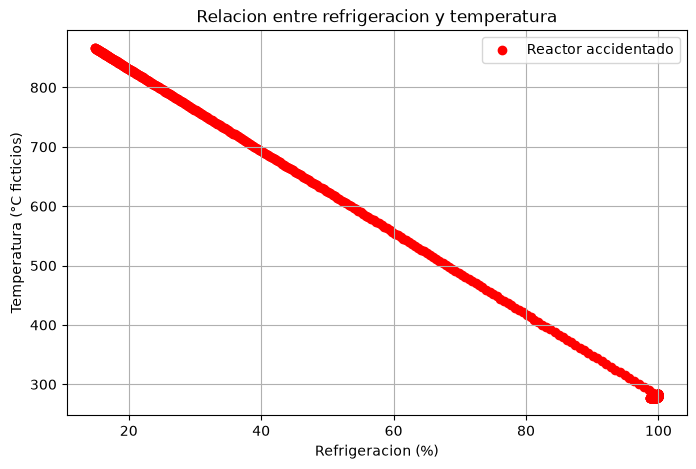

In [3]:
plt.figure(figsize=(8, 5))

plt.scatter(
    refrigeracion_accidente,
    temperatura_accidente,
    color="red",
    label="Reactor accidentado"
)

plt.title("Relacion entre refrigeracion y temperatura")
plt.xlabel("Refrigeracion (%)")
plt.ylabel("Temperatura (°C ficticios)")
plt.grid(True)
plt.legend()

plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    potencia_accidente,
    temperatura_accidente,
    color="orange",
    label="Reactor accidentado"
)

plt.title("Relacion entre potencia y temperatura")
plt.xlabel("Potencia (%)")
plt.ylabel("Temperatura (°C ficticios)")
plt.grid(True)
plt.legend()

plt.show()